# Connect media bias to neighbouring terms

Draw how the papers link **media bias, bias, misinformation, disinformation, fake news and propaganda**. Each node is a merged term of MBDef; each arrow points from a subtype to its supertype, and its label counts the **distinct papers** that report the relation, from their subtype and supertype statements together. When the papers report both directions, both arrows are drawn.

## Load MBDef
`load()` reads MBDef's five tables from `$DATA_ROOT/MBDef/data/`, where `uv run mbdef data fetch MBDef/` puts them after checking each file's sha256. Pass a folder, `load("path/to/data")`, to read another copy of the parquet files. Each table is a [polars](https://docs.pola.rs/) DataFrame.

In [1]:
import json
from pathlib import Path

from mbdef.analysis import load

OUTPUTS = Path("outputs")  # tutorials/outputs/, not tracked by git
data = load()

## Extract the hierarchy and select the terms
A subtype or supertype that a paper names is an edge when the `terms` table links it to a merged term (`links_to`). The figure keeps the union of **all shortest undirected paths** between every pair of the six terms, then every directed relation between the kept terms: direction is ignored only to find the connecting paths. A single paper is enough for an arrow.

The node positions are fixed in [`network_layout.json`](../src/mbdef/analysis/network_layout.json) to match the publication figure; arrow routes and paper counts are computed from the data. A release that brings in other connecting terms needs their positions there.

In [2]:
from mbdef.analysis.connections import (
    ANCHORS,
    connections_figure,
    network_inputs,
)

evidence, requested, labels, self_relations = network_inputs(data, ANCHORS)
print("Directed relations in the whole hierarchy:", len(evidence))
print("Relations of a term to itself, left out:", len(self_relations))

Directed relations in the whole hierarchy: 8853
Relations of a term to itself, left out: 16


Concept connections: outputs/media-bias-concept-connection/media-bias-concept-connection.svg (24 terms, 63 relations)
24 terms; 63 directed relations
Disconnected pairs of the six: []


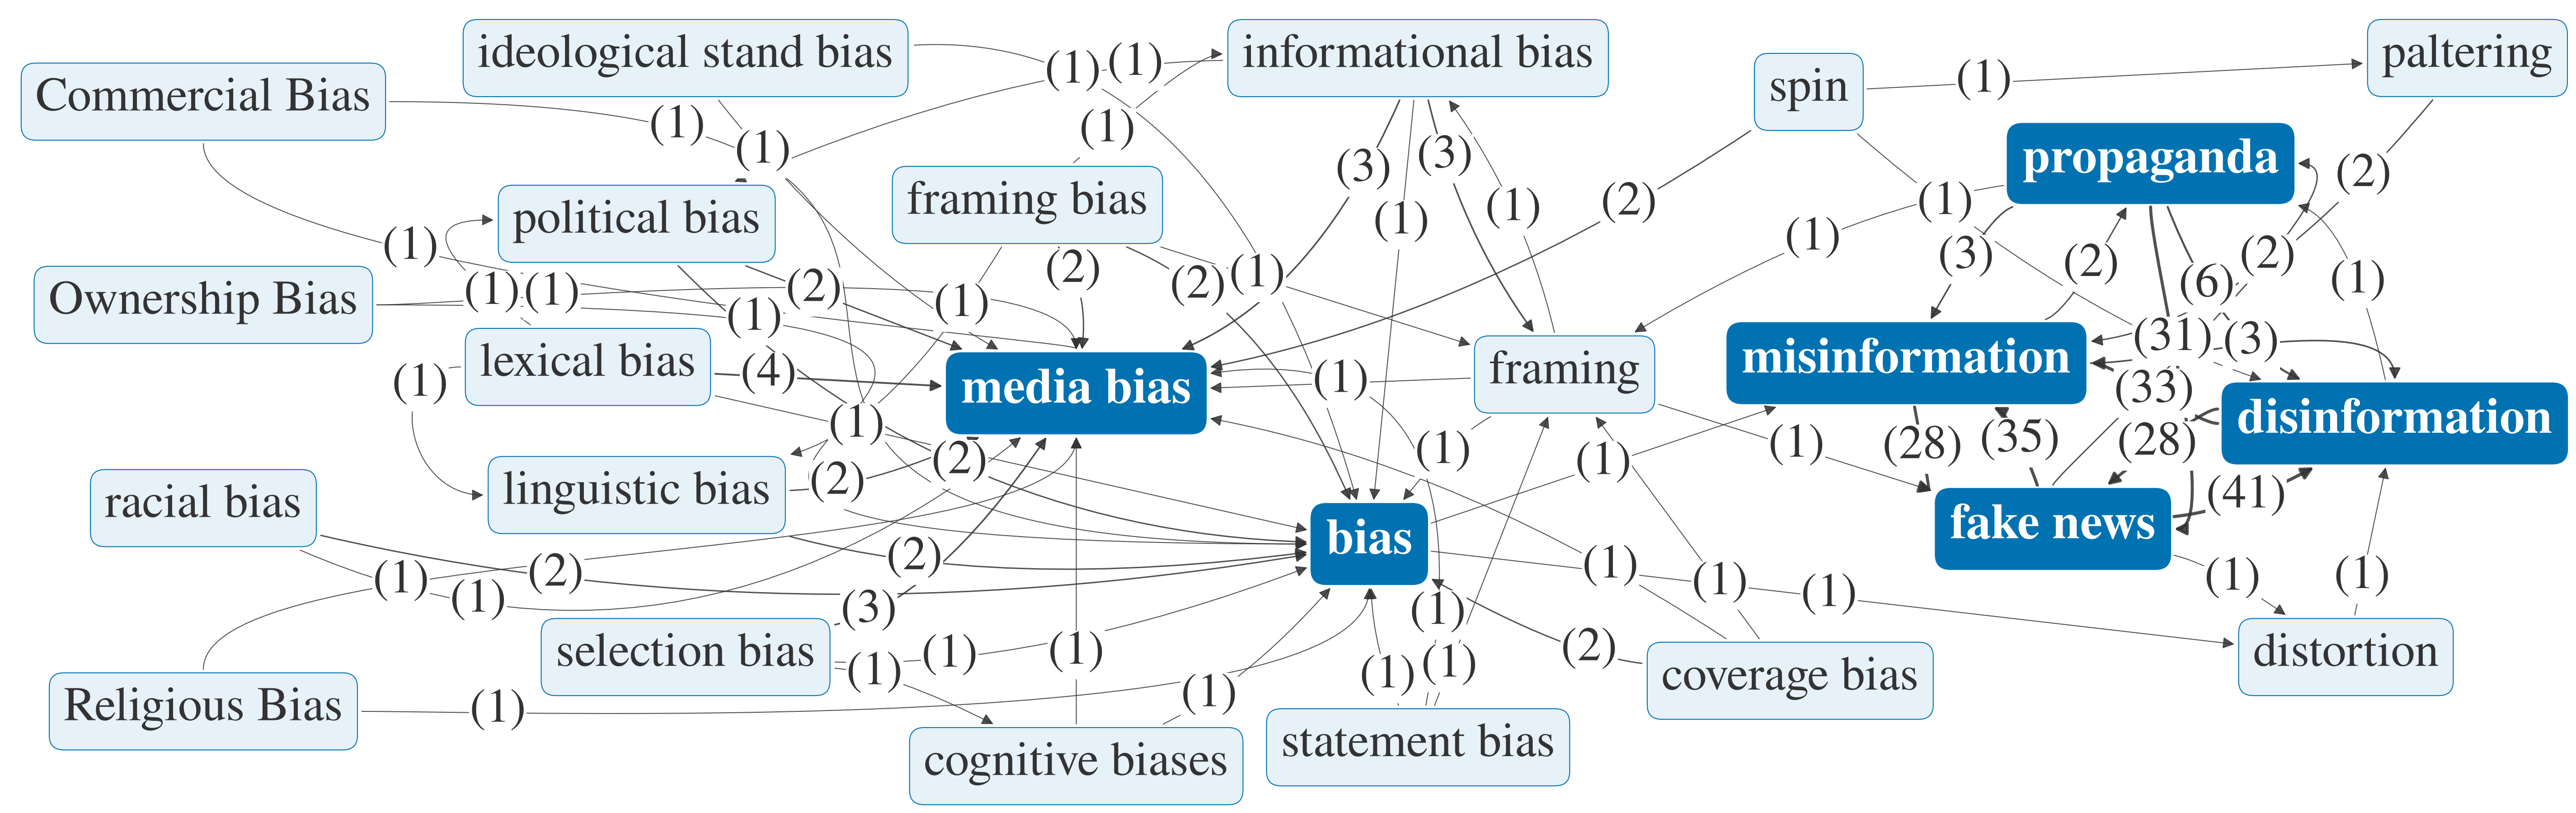

In [3]:
from IPython.display import Image, display

network_output = OUTPUTS / "media-bias-concept-connection"
audit_file = network_output / "relations.json"
connections_figure(
    network_output, evidence, requested, audit_path=audit_file, node_labels=labels
)
audit = json.loads(audit_file.read_text())
print(f"{len(audit['nodes'])} terms; {len(audit['edges'])} directed relations")
print("Disconnected pairs of the six:", audit["disconnected_pairs"])
display(Image(filename=str(network_output / "media-bias-concept-connection.png")))

## Trace an arrow back to its papers
The audit file keeps every claim behind an arrow: the paper, the Extracted Concept, the field (subtypes or supertypes) and the words as written. Several claims from one paper count once.

In [4]:
names = audit["node_labels"]
for edge in audit["edges"][:5]:
    print(
        f"{names[edge['source']]} → {names[edge['target']]}: {edge['distinct_papers']} papers"
    )
    print("  Papers:", sorted({claim["paper_id"] for claim in edge["evidence"]}))

cognitive biases → media bias: 1 papers
  Papers: ['hash_6f886b85bd12b2eb__d85cf77d5bb3d78f']
cognitive biases → bias: 1 papers
  Papers: ['pdf-194acc82da05dc35f564cc037923aeffa2938e3275352f177a9b8ea43269503a']
framing bias → media bias: 2 papers
  Papers: ['hash_27e8ef12483b802b__12d71419f78f5044', 'hash_6f886b85bd12b2eb__d85cf77d5bb3d78f']
framing bias → informational bias: 1 papers
  Papers: ['doi_10.48550_arxiv.2104.00336__b7be7a6ac7e927361df9561c5a39da30945186df__ba0f4a74e8a306c3']
framing bias → linguistic bias: 1 papers
  Papers: ['hash_6f886b85bd12b2eb__d85cf77d5bb3d78f']


### Interpretation
The network shows how the literature ties media bias to neighbouring ideas that reach beyond media bias in a strict sense, which can inform a taxonomy's scope and boundaries. Extracted claims, even repeated ones, do not establish accepted subtype relations: the network is a starting point for expert consolidation, not a validated taxonomy. The [MBDef Explorer](https://media-bias-group.github.io/MBDef/)'s taxonomy and relations tabs show the same links interactively.